# 03 — Principal Component Analysis: The Axes of Modern NBA Roles

**Project:** Positionless NBA Player Archetypes · **Season:** 2025-26 · **Population:** 379 players with ≥ 500 minutes

The previous notebook produced a 13-feature description of each player's role: shot diet, creation, rebounding and
defensive activity. Thirteen dimensions cannot be looked at directly, and many of them move together (players who
shoot at the rim also rebound and block shots). **Principal Component Analysis (PCA)** finds the few directions along
which players differ the most, and expresses each player as a position on those directions.

This notebook answers four questions:

| # | Question | Section |
|---|---|---|
| 1 | How many independent dimensions of playing style are there really? | §2 Scree plot & retention |
| 2 | What does each dimension *mean* in basketball terms? | §3 Loadings & extreme players |
| 3 | Where do players and listed positions sit in this space? | §4 Projection & biplot |
| 4 | Are the axes stable, or an artefact of the scaling choice? | §5 Robustness |

**Role in the pipeline.** PCA here is primarily a tool for **interpretation and visualisation**: it names the
axes of variation and gives every later result (clusters, anomalies) a map to be drawn on. Whether clustering should
run on PCA scores or on the full feature set is decided at the end (§6).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from sklearn.decomposition import PCA

pd.set_option('display.max_columns', 40)
pd.set_option('display.width', 160)
sns.set_theme(style='whitegrid', context='notebook')

DATA = Path('../data') if Path('../data').exists() else Path('data')
POS_ORDER = ['PG', 'SG', 'SF', 'PF', 'C']
PALETTE = dict(zip(POS_ORDER, sns.color_palette('tab10', 5)))

---
## 1. Load the Scaled Feature Matrix

**Goal.** Load the Yeo-Johnson-scaled features (the version chosen for PCA and clustering) and separate the model
inputs from the metadata.

**Why it matters.** PCA is driven by variances. If features were on different scales, the feature with the largest
numeric range would dominate the first component regardless of its basketball importance. The power-transformed
features all have mean 0 and standard deviation 1, so every feature enters PCA with equal weight, and the components
reflect *correlation structure*, not units.

**What to look for.** 379 rows, 13 features with mean ≈ 0 and std ≈ 1, no missing values.

In [2]:
power = pd.read_csv(DATA / 'processed' / 'features_power.csv')
standard = pd.read_csv(DATA / 'processed' / 'features_standard.csv')
raw = pd.read_csv(DATA / 'processed' / 'features_raw.csv')

META = ['player_id', 'player', 'team', 'pos', 'pos_played', 'age', 'g', 'mp',
        'pg_percent', 'sg_percent', 'sf_percent', 'pf_percent', 'c_percent']
FEAT = [c for c in power.columns if c not in META]
X = power[FEAT]
print('players:', len(X), '| features:', len(FEAT), '| missing:', int(X.isna().sum().sum()))
X.agg(['mean', 'std']).round(3)

players: 379 | features: 13 | missing: 0


,x3p_ar,corner3_rate,mid_share,rim_share,f_tr,usg_percent,ast_percent,tov_percent,percent_assisted_x2p_fg,orb_percent,drb_percent,blk_percent,stl_percent
mean,-0.000,0.000,-0.000,-0.000,0.000,0.000,-0.000,0.000,-0.000,-0.000,0.000,0.000,-0.000
std,1.001,1.001,1.001,1.001,1.001,1.001,1.001,1.001,1.001,1.001,1.001,1.001,1.001


---
## 2. How Many Dimensions? Scree Plot & Component Retention

**Goal.** Fit PCA with all 13 components and decide how many carry real structure.

**How PCA works, briefly.** PCA rotates the 13-dimensional feature space so that the first new axis (PC1) points in
the direction of maximum variance across players, PC2 in the direction of maximum *remaining* variance at right angles
to PC1, and so on. Each component's **eigenvalue** is the variance along it; since every scaled feature has variance 1,
the eigenvalues sum to 13, and an eigenvalue of 4 means that component carries as much variance as four original
features.

**Three retention rules are compared:**
1. **Elbow:** where the scree curve flattens.
2. **Kaiser criterion:** keep components with eigenvalue > 1 (they explain more than a single original feature).
3. **Parallel analysis:** the most rigorous of the three. Shuffle each feature independently (destroying all
   correlations between features while keeping their distributions), refit PCA 200 times, and keep only components whose
   eigenvalue beats the 95th percentile of these random eigenvalues. A component that does not beat random data is
   noise.

**What to look for.** The point where the real eigenvalues (blue) drop below the random-data line (red): components
to the left of it carry genuine structure.

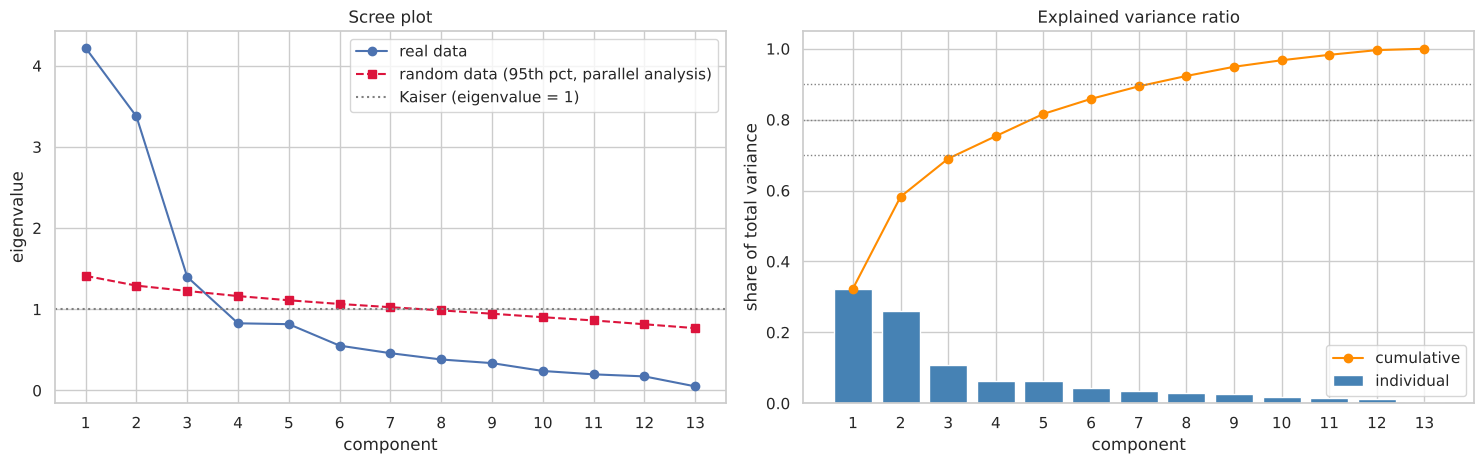

,eigenvalue,random 95th pct,explained %,cumulative %,Kaiser (>1),parallel analysis
PC1,4.22,1.41,32.37,32.37,keep,keep
PC2,3.38,1.29,25.90,58.27,keep,keep
PC3,1.40,1.23,10.73,69.01,keep,keep
PC4,0.83,1.16,6.35,75.36,,
PC5,0.82,1.11,6.27,81.62,,
PC6,0.55,1.07,4.24,85.86,,
PC7,0.46,1.03,3.53,89.39,,
PC8,0.38,0.99,2.93,92.32,,


In [3]:
pca = PCA().fit(X)
eig = pca.explained_variance_
evr = pca.explained_variance_ratio_

rng = np.random.default_rng(0)
random_eig = np.array([PCA().fit(np.column_stack([rng.permutation(X[c].values) for c in FEAT])).explained_variance_
                       for _ in range(200)])
threshold = np.percentile(random_eig, 95, axis=0)

comp = np.arange(1, len(FEAT) + 1)
fig, ax = plt.subplots(1, 2, figsize=(15, 4.8))
ax[0].plot(comp, eig, 'o-', label='real data')
ax[0].plot(comp, threshold, 's--', color='crimson', label='random data (95th pct, parallel analysis)')
ax[0].axhline(1, color='grey', ls=':', label='Kaiser (eigenvalue = 1)')
ax[0].set(title='Scree plot', xlabel='component', ylabel='eigenvalue', xticks=comp); ax[0].legend()

ax[1].bar(comp, evr, color='steelblue', label='individual')
ax[1].plot(comp, evr.cumsum(), 'o-', color='darkorange', label='cumulative')
for t in (0.7, 0.8, 0.9):
    ax[1].axhline(t, color='grey', ls=':', lw=1)
ax[1].set(title='Explained variance ratio', xlabel='component', ylabel='share of total variance', xticks=comp)
ax[1].legend(); plt.tight_layout(); plt.show()

retention = pd.DataFrame({'eigenvalue': eig, 'random 95th pct': threshold,
                          'explained %': evr * 100, 'cumulative %': evr.cumsum() * 100},
                         index=[f'PC{i}' for i in comp]).round(2)
retention['Kaiser (>1)'] = np.where(retention['eigenvalue'] > 1, 'keep', '')
retention['parallel analysis'] = np.where(retention['eigenvalue'] > retention['random 95th pct'], 'keep', '')
retention.head(8)

### Findings: Dimensionality
- **Three components carry real structure.** Kaiser and parallel analysis agree exactly: PC1–PC3 have eigenvalues of
  4.22, 3.38 and 1.40, all above both thresholds; PC4 (0.83) falls below the random-data line (1.16).
- **PC1 + PC2 alone explain 58%** of all variation in 13 features, and the first three explain **69%**. Two numbers
  per player capture more than half of what distinguishes their roles, which makes 2-D maps (§4) unusually faithful.
- The curve has a clear **elbow after PC3**; from PC4 on, each component adds only 2–6%.
- **PC4 and PC5 have almost identical eigenvalues (0.83 vs. 0.82).** When two components carry the same variance,
  PCA cannot separate them reliably: any rotation of the two is equally valid. They will not be interpreted
  individually (confirmed in §5).

---
## 3. What Does Each Component Mean? Loadings

**Goal.** Interpret each retained component through its **loadings**: the weight of each original feature in the
component.

**How to read loadings.** A player's score on a component is the weighted sum of the player's scaled features, using
the loadings as weights. A large positive loading means a high value of that feature pushes the player toward the
positive end; a large negative loading pushes toward the negative end. Features with loadings near 0 do not matter for
that component. Since each component is a unit vector, the squared loadings sum to 1, and |loading| ≳ 0.3 marks a
feature as important.

**Sign convention.** The sign of a principal component is arbitrary: flipping every loading and every score gives
an equally valid solution. To make the axes readable (and stable across reruns), each component is oriented so that a
chosen **anchor feature** has a positive loading: PC1 → rim share (interior is positive), PC2 → usage (on-ball creation
is positive), PC3 → steal rate.

**What to look for.** For each component, the group of features with large loadings of the *same* sign (one end of
the axis) versus the opposite sign (the other end). Features sharing a component define a single underlying concept.

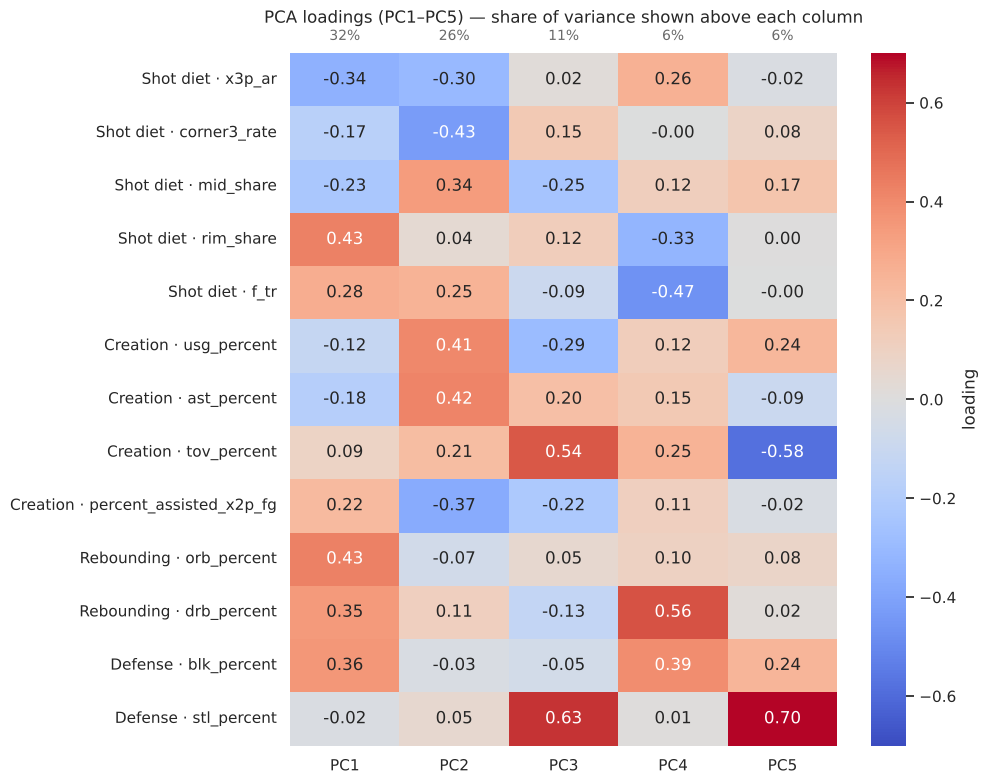

In [4]:
ANCHORS = ['rim_share', 'usg_percent', 'stl_percent', 'drb_percent', 'stl_percent']
N_SHOW = 5
pcs = [f'PC{i}' for i in range(1, N_SHOW + 1)]

signs = np.array([np.sign(pca.components_[i, FEAT.index(a)]) for i, a in enumerate(ANCHORS)])
loadings = pd.DataFrame((pca.components_[:N_SHOW] * signs[:, None]).T, index=FEAT, columns=pcs)
scores = pd.DataFrame(pca.transform(X)[:, :N_SHOW] * signs, columns=pcs)

GROUP = {'x3p_ar': 'Shot diet', 'corner3_rate': 'Shot diet', 'mid_share': 'Shot diet', 'rim_share': 'Shot diet',
         'f_tr': 'Shot diet', 'usg_percent': 'Creation', 'ast_percent': 'Creation', 'tov_percent': 'Creation',
         'percent_assisted_x2p_fg': 'Creation', 'orb_percent': 'Rebounding', 'drb_percent': 'Rebounding',
         'blk_percent': 'Defense', 'stl_percent': 'Defense'}
labels = [f'{GROUP[f]} · {f}' for f in FEAT]

fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(loadings.set_axis(labels), annot=True, fmt='.2f', cmap='coolwarm', vmin=-0.7, vmax=0.7,
            cbar_kws={'label': 'loading'}, ax=ax)
for i, p in enumerate(pcs):
    ax.text(i + 0.5, -0.25, f'{evr[i]:.0%}', ha='center', fontsize=10, color='dimgrey')
ax.set_title('PCA loadings (PC1–PC5) — share of variance shown above each column', pad=22)
plt.tight_layout(); plt.show()

**Goal.** Validate the interpretation with real players: list the five players at each end of PC1–PC3.

**Why it matters.** Loadings are abstract. If the interpretation of an axis is correct, the players at its extremes
should be instantly recognisable examples of the two opposite roles. This is the same face-validity check used for
the feature space in the previous notebook.

**What to look for.** Whether the extremes match the label suggested by the loadings, and whether they cross listed
positions.

In [5]:
names = pd.Series(power['player'].values)
pos = pd.Series(power['pos'].values)
ext = {}
for p in pcs[:3]:
    hi, lo = scores[p].nlargest(5).index, scores[p].nsmallest(5).index
    ext[(p, 'highest (+)')] = [f'{names[i]} ({pos[i]})' for i in hi]
    ext[(p, 'lowest (−)')] = [f'{names[i]} ({pos[i]})' for i in lo]
pd.DataFrame(ext, index=range(1, 6))

PC1                                                PC2                                           PC3                        
             highest (+)           lowest (−)                   highest (+)                lowest (−)         highest (+)              lowest (−)
1       Moussa Cisse (C)  Gary Trent Jr. (SG)    Giannis Antetokounmpo (PF)        Nicolas Batum (PF)     Lonzo Ball (PG)   Tim Hardaway Jr. (SG)
2  Mitchell Robinson (C)    Gabe Vincent (PG)  Shai Gilgeous-Alexander (PG)           Josh Green (SG)      Kris Dunn (PG)         Joel Embiid (C)
3        Rudy Gobert (C)      Tyus Jones (PG)              Luka Dončić (PG)        Spencer Jones (SF)      Dru Smith (SG)      Rui Hachimura (PF)
4      Dwight Powell (C)  Keaton Wallace (PG)                Ja Morant (PG)            Dean Wade (PF)   John Konchar (SG)        Jett Howard (SF)
5          Adem Bona (C)   Ryan Nembhard (PG)          Cade Cunningham (PG)  Dorian Finney-Smith (PF)  Day'Ron Sharpe (C)  Kristaps Porziņģis (C)

### Findings: The three axes of NBA roles

**PC1 (32%): Interior ↔ Perimeter.** Positive loadings: rim share (0.43), ORB% (0.43), BLK% (0.36), DRB% (0.35),
free-throw rate (0.28). Negative: 3PA rate (−0.34), mid-range share (−0.23).
*Highest:* Moussa Cisse, Mitchell Robinson, Rudy Gobert, Dwight Powell, Adem Bona, all rim-running, rebounding centres.
*Lowest:* Gary Trent Jr., Gabe Vincent, Tyus Jones, Keaton Wallace, Ryan Nembhard, perimeter guards who live outside the paint.
This is the classic "big vs. small" axis, and it is the only one listed positions describe well (§4).

**PC2 (26%): On-ball creator ↔ Off-ball finisher.** Positive: usage (0.41), AST% (0.42), mid-range share (0.34), free-throw
rate (0.25), TOV% (0.21). Negative: corner-3 rate (−0.43), % of 2s assisted (−0.37), 3PA rate (−0.30).
*Highest:* Giannis Antetokounmpo, Shai Gilgeous-Alexander, Luka Dončić, Ja Morant, Cade Cunningham, the players
whose teams run the offense through them.
*Lowest:* Nicolas Batum, Josh Green, Spencer Jones, Dean Wade, Dorian Finney-Smith, spot-up corner shooters whose
baskets are created by others.
The axis is **largely independent of size**: the top five are a power forward and four point guards, and centres
Jokić and Embiid rank 8th and 15th of 379.

**PC3 (11%): Disruptor / connector ↔ Self-sufficient scorer.** Positive: steal rate (0.63), TOV% (0.54), AST% (0.20).
Negative: usage (−0.29), mid-range share (−0.25), % of 2s assisted (−0.22).
*Highest:* Lonzo Ball, Kris Dunn, Dru Smith, John Konchar, Day'Ron Sharpe: low-usage players who generate steals and
move the ball (their turnover rate is high because they use few plays, almost all of them passes).
*Lowest:* Tim Hardaway Jr., Joel Embiid, Rui Hachimura, Jett Howard, Kristaps Porziņģis: scorers who finish plays
without forcing turnovers either way.

**PC4–PC5** (6% each) mix defensive rebounding, blocks, free-throw rate and steals in ways that change between
scalers (§5); they are not interpreted.

---
## 4. The Player Map: Projection onto PC1 × PC2

**Goal.** Place every player on the plane defined by the two main axes and colour the points by position, once by
**listed** position and once by **most-played** position (play-by-play).

**Why it matters.** This is the most direct visual test of the project's premise. If the five positions were
natural groups, they would form five separate clouds. If roles are continuous, the colours will overlap and form a
gradient instead. Comparing listed vs. played position shows whether actual deployment is more consistent with the
data than roster labels.

**What to look for.**
- How the colours are arranged along PC1 (horizontal) versus PC2 (vertical).
- Overlap between neighbouring positions.
- Where well-known players (annotated) land, and which players of *different* positions sit next to each other.

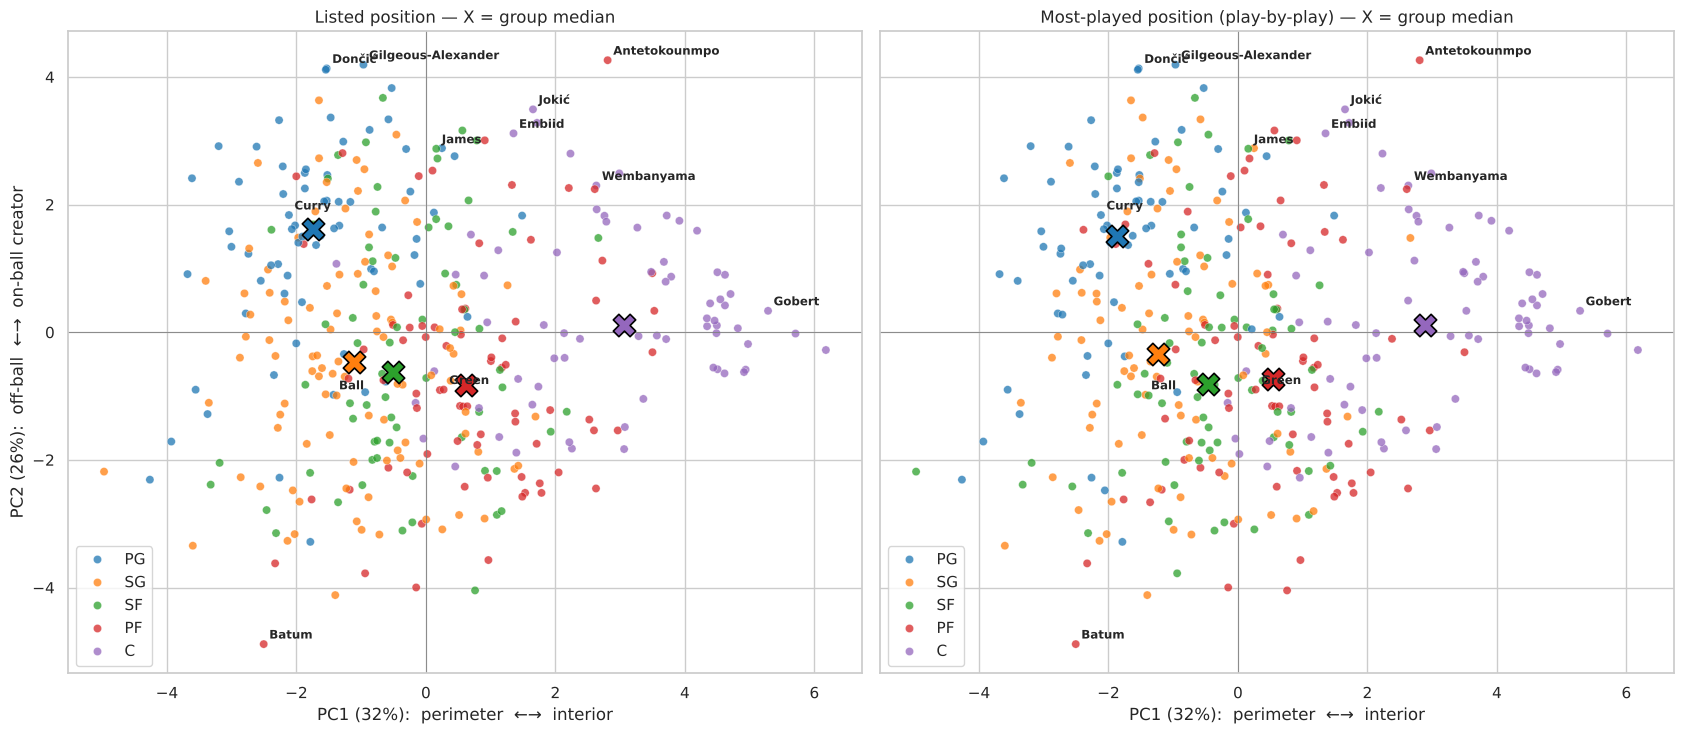

In [6]:
proj = pd.concat([power[['player', 'pos', 'pos_played']], scores], axis=1)
STARS = ['Nikola Jokić', 'Giannis Antetokounmpo', 'Shai Gilgeous-Alexander', 'Luka Dončić', 'Stephen Curry',
         'Rudy Gobert', 'Victor Wembanyama', 'Draymond Green', 'Nicolas Batum', 'Joel Embiid', 'Lonzo Ball',
         'LeBron James']

fig, ax = plt.subplots(1, 2, figsize=(17, 7.5), sharex=True, sharey=True)
for a, col, title in [(ax[0], 'pos', 'Listed position'), (ax[1], 'pos_played', 'Most-played position (play-by-play)')]:
    sns.scatterplot(data=proj, x='PC1', y='PC2', hue=col, hue_order=POS_ORDER, palette=PALETTE,
                    s=35, alpha=0.75, edgecolor='white', linewidth=0.3, ax=a)
    med = proj.groupby(col)[['PC1', 'PC2']].median()
    for p, (x, y) in med.iterrows():
        a.scatter(x, y, s=260, marker='X', color=PALETTE[p], edgecolor='black', linewidth=1.2, zorder=5)
    for s in STARS:
        r = proj[proj['player'] == s]
        if len(r):
            a.annotate(s.split()[-1], (r['PC1'].iat[0], r['PC2'].iat[0]), xytext=(4, 4),
                       textcoords='offset points', fontsize=8.5, weight='bold', zorder=6)
    a.axhline(0, color='grey', lw=0.6); a.axvline(0, color='grey', lw=0.6)
    a.set(title=f'{title} — X = group median',
          xlabel=f'PC1 ({evr[0]:.0%}):  perimeter  ←→  interior',
          ylabel=f'PC2 ({evr[1]:.0%}):  off-ball  ←→  on-ball creator')
    a.legend(title=None, loc='lower left')
plt.tight_layout(); plt.show()

**Goal.** Quantify what the map shows: how much of each component listed position (and played position) explains,
using η² (the share of a variable's variance that lies between groups; see the EDA notebook).

**What to look for.** A high η² means the component is essentially "position"; a low η² means the component
describes something the position labels do not capture.

In [7]:
def eta_squared(values, groups):
    d = pd.DataFrame({'x': values, 'g': groups})
    grand = d['x'].mean()
    between = d.groupby('g')['x'].apply(lambda s: len(s) * (s.mean() - grand) ** 2).sum()
    return between / ((d['x'] - grand) ** 2).sum()

eta = pd.DataFrame({'explained variance %': evr[:N_SHOW] * 100,
                    'η² listed pos': [eta_squared(scores[p], power['pos']) for p in pcs],
                    'η² played pos': [eta_squared(scores[p], power['pos_played']) for p in pcs]},
                   index=pcs).round(2)
med = proj.groupby('pos')[pcs[:3]].median().loc[POS_ORDER].T.round(2)
med.columns = [f'median {p}' for p in POS_ORDER]
pd.concat([eta, med], axis=1).loc[pcs[:3]]

,explained variance %,η² listed pos,η² played pos,median PG,median SG,median SF,median PF,median C
PC1,32.37,0.59,0.61,-1.74,-1.12,-0.50,0.62,3.07
PC2,25.90,0.16,0.13,1.62,-0.46,-0.62,-0.82,0.11
PC3,10.73,0.13,0.10,0.81,0.04,-0.37,-0.30,-0.43


### Biplot: features and players on the same map

**Goal.** Overlay the feature loadings as arrows on the player map.

**How to read it.** Each arrow points in the direction in which that feature *increases*; its length shows how
strongly the feature is represented in the PC1–PC2 plane. Players lying in the direction of an arrow are high on that
feature. Arrows pointing the same way are positively correlated; opposite arrows are negatively correlated;
perpendicular arrows are roughly unrelated.

**What to look for.** Which features define each "corner" of the map, and which arrows are short (poorly
represented in two dimensions and left to PC3+).

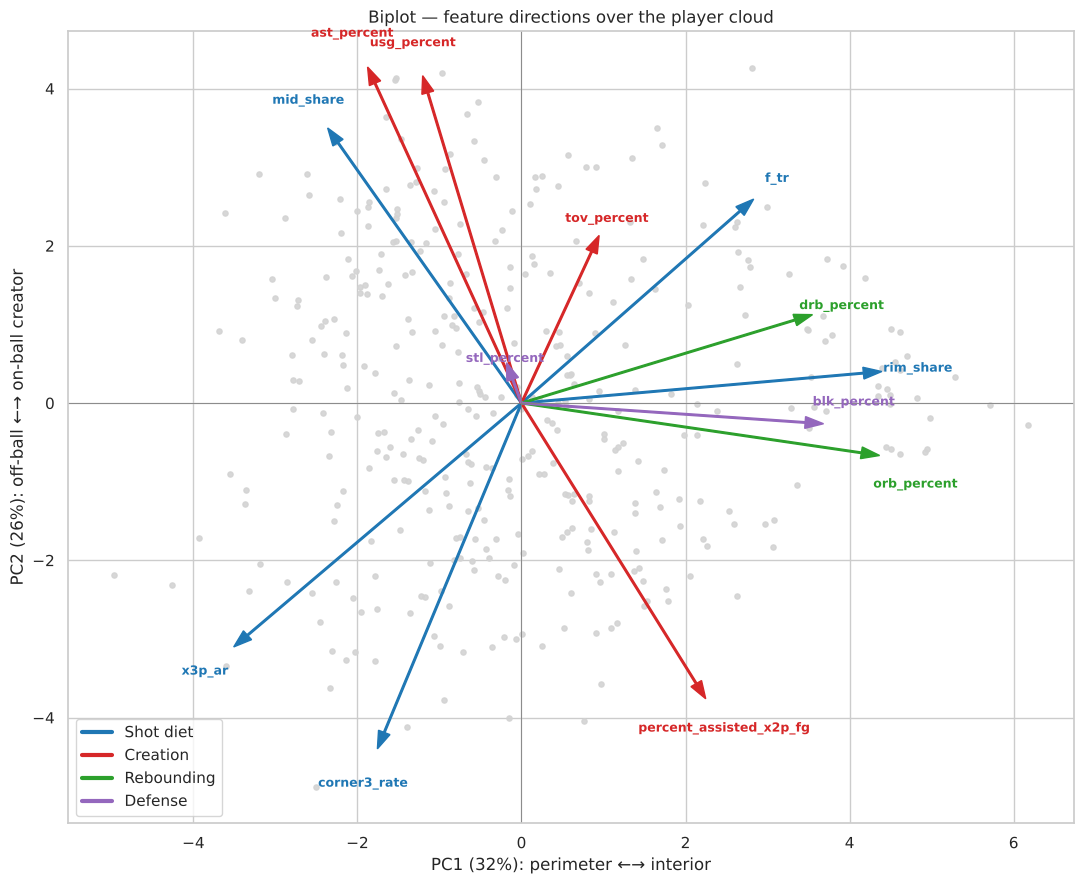

In [8]:
fig, ax = plt.subplots(figsize=(11, 9))
ax.scatter(scores['PC1'], scores['PC2'], s=14, color='lightgrey', alpha=0.9)
scale = np.abs(scores[['PC1', 'PC2']]).max().min() * 0.9 / np.abs(loadings[['PC1', 'PC2']]).max().max()
gcol = {'Shot diet': 'tab:blue', 'Creation': 'tab:red', 'Rebounding': 'tab:green', 'Defense': 'tab:purple'}
for f in FEAT:
    x, y = loadings.loc[f, 'PC1'] * scale, loadings.loc[f, 'PC2'] * scale
    ax.arrow(0, 0, x, y, color=gcol[GROUP[f]], width=0.02, head_width=0.15, length_includes_head=True)
    dy = {'blk_percent': 0.3, 'orb_percent': -0.3}.get(f, 0)     # keep two nearly parallel labels apart
    ax.text(x * 1.1, y * 1.1 + dy, f, color=gcol[GROUP[f]], fontsize=9, ha='center', va='center', weight='bold')
for g, c in gcol.items():
    ax.plot([], [], color=c, lw=3, label=g)
ax.axhline(0, color='grey', lw=0.6); ax.axvline(0, color='grey', lw=0.6)
ax.set(title='Biplot — feature directions over the player cloud',
       xlabel=f'PC1 ({evr[0]:.0%}): perimeter ←→ interior', ylabel=f'PC2 ({evr[1]:.0%}): off-ball ←→ on-ball creator')
ax.legend(loc='lower left'); plt.tight_layout(); plt.show()

### Findings: The player map
- **PC1 is largely "position"** (η² ≈ 0.59 for listed, 0.61 for played position). The group medians form an orderly
  staircase from PG (−1.7) through SG, SF and PF to C (+3.1). But it is a *gradient*: neighbouring positions overlap
  heavily, and only the centres separate clearly.
- **PC2 is largely *not* position** (η² ≈ 0.16 listed, 0.13 played). Only point guards lean toward the creator end
  (median +1.6); SG, SF, PF and C medians all sit between −0.8 and +0.1, while their *individual* players spread across
  the whole axis. The second-largest dimension of style, **on-ball creation, is almost invisible to the five-position
  system**. Giannis (PF), Jokić (C) and Dončić (PG) all sit at the top of the map despite different labels.
- **PC3 is barely position at all** (η² ≈ 0.13 / 0.10).
- The **played-position** map is not much cleaner than the listed one: coaches' actual usage is still a one-dimensional
  "size" label, so it also misses PC2 and PC3.
- **Biplot:** the interior features (rim share, ORB%, BLK%, DRB%) form one bundle pointing right; the creation
  features (usage, AST%, mid-range share) point up; off-ball shooting (corner-3 rate, % assisted, 3PA rate) points
  down and left. % of 2s assisted points down and right: off-ball finishers inside (lob-catching centres) and outside
  (spot-up wings) share it. Steal rate's arrow is almost zero and TOV%'s is among the shortest: both live mostly on PC3.

---
## 5. Robustness: Are the Axes an Artefact of the Scaling?

**Goal.** Refit PCA on the `StandardScaler` version of the features and compare the components with those from the
power-transformed version.

**Why it matters.** The previous notebook chose the Yeo-Johnson transform because it gives a better-balanced geometry.
If the main axes changed meaning under a different, equally defensible scaler, any archetype built on them would be
fragile. Two measures are used:
- **|cosine| between loading vectors:** 1 = the same direction in feature space (sign ignored), 0 = unrelated.
- **|correlation| between player scores:** 1 = players are ordered identically along the component.

**What to look for.** Values near 1 for the retained components. Low values for PC4–PC5 would confirm the
near-equal-eigenvalue problem noted in §2.

In [9]:
pca_std = PCA().fit(standard[FEAT])
sc_std = pca_std.transform(standard[FEAT])
sc_pow = pca.transform(X)
robust = pd.DataFrame({
    'explained % (power)': evr[:N_SHOW] * 100,
    'explained % (standard)': pca_std.explained_variance_ratio_[:N_SHOW] * 100,
    '|cos| loadings': [abs(pca.components_[i] @ pca_std.components_[i]) for i in range(N_SHOW)],
    '|corr| scores': [abs(np.corrcoef(sc_pow[:, i], sc_std[:, i])[0, 1]) for i in range(N_SHOW)],
}, index=pcs).round(3)
robust

,explained % (power),explained % (standard),|cos| loadings,|corr| scores
PC1,32.372,32.741,0.996,0.976
PC2,25.900,25.791,0.996,0.989
PC3,10.734,10.819,0.996,0.985
PC4,6.350,6.239,0.339,0.335
PC5,6.268,6.010,0.336,0.321


### Findings: Robustness
- **PC1–PC3 are essentially identical under both scalers:** |cos| ≈ 0.996 for all three loading vectors, player scores
  correlate at 0.98–0.99, and the explained-variance shares match within half a percentage point. The three axes are a
  property of the *data*, not of the transform.
- **PC4 and PC5 are not stable** (|cos| ≈ 0.34). This is the expected consequence of their near-identical eigenvalues:
  the two directions are freely mixed by small changes in the data. Combined with failing parallel analysis, this
  confirms they should not be interpreted.

---
## 6. Decision for Clustering & Export

**Question.** Should the clustering algorithms run on the PCA scores or on the full 13 scaled features?

| Option | For | Against |
|---|---|---|
| **3 PCs** (69% of variance) | Removes noise; easy to visualise | Discards 31% of variance, including real (if smaller) role differences, e.g. free-throw and defensive-rebounding nuances that define some archetypes |
| **5 PCs** (82%) | Denoised but more complete | PC4–PC5 are unstable, so cluster boundaries could depend on an arbitrary rotation |
| **All 13 scaled features** | Keeps all information; redundancy was already removed (max VIF 8.8) | Slightly noisier distances |

**Decision.**
- **Primary clustering input: the full 13 power-transformed features.** Redundancy was handled at the feature-selection
  stage, so PCA is not needed to remove duplicated information. With only 13 features and 379 players, dimensionality
  is not a problem for k-means, hierarchical clustering or GMM.
- **Sensitivity check: clustering on the first 3 PC scores**, to test whether archetypes survive when only the
  dominant structure is kept.
- **PCA's main role from here on is the map:** every clustering and anomaly result will be drawn on the PC1 × PC2 plane
  and described in terms of the three named axes.

**Export.** PC scores (oriented as in §3), loadings and explained variance are saved for the next notebooks.

In [10]:
out = DATA / 'processed'
pca_scores = pd.concat([power[META], scores], axis=1)
pca_scores.to_csv(out / 'pca_scores.csv', index=False)
loadings.to_csv(out / 'pca_loadings.csv')
pd.DataFrame({'explained_variance_ratio': evr, 'eigenvalue': eig},
             index=[f'PC{i}' for i in comp]).to_csv(out / 'pca_explained_variance.csv')
for f in ['pca_scores.csv', 'pca_loadings.csv', 'pca_explained_variance.csv']:
    print('saved', out / f)

saved ../data/processed/pca_scores.csv
saved ../data/processed/pca_loadings.csv
saved ../data/processed/pca_explained_variance.csv


---
## Summary

| Question | Answer |
|---|---|
| How many real dimensions? | **3** (Kaiser and parallel analysis agree), explaining **69%** of variance; PC1 + PC2 = 58% |
| PC1 (32%) | **Interior ↔ Perimeter:** rim shots, offensive rebounds, blocks vs. three-point volume |
| PC2 (26%) | **On-ball creator ↔ Off-ball finisher:** usage, assists, mid-range, free throws vs. corner threes and assisted baskets |
| PC3 (11%) | **Disruptor / connector ↔ Self-sufficient scorer:** steals, ball movement vs. usage and mid-range scoring |
| Does position explain the axes? | PC1 yes (η² ≈ 0.6); **PC2 and PC3 hardly at all (η² ≤ 0.16)** |
| Are the axes robust? | PC1–PC3 identical under Standard and Power scaling (\|cos\| ≈ 0.996); PC4–PC5 unstable |
| Clustering input | Full 13 power-transformed features (primary); 3 PC scores (sensitivity check) |

**The key insight:** the five-position system is effectively a **one-dimensional** description of players (size,
PC1), while the data shows **at least three** independent dimensions of role. On-ball creation, the second-largest
source of variation, is almost entirely missed by position labels. This is exactly the gap that data-driven archetypes
can fill.

**Next: `04_Clustering.ipynb`.** k-means (choosing k with inertia and silhouette), hierarchical clustering (Ward
linkage and dendrogram), Gaussian Mixture Models with soft membership, compared on the same data and drawn on this map.